# Combined Data Preprocessing and EDA Pipeline

This notebook integrates the preprocessing and EDA work completed by all group members for the Precision Fertilizer Recommendation project.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer

DATA_PATH = Path("data/raw/data_core.csv")
PLOT_DIR = Path("results/eda_visualizations")
OUTPUT_DIR = Path("results/outputs")

PLOT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (8000, 9)


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26.0,52.0,38.0,Sandy,Maize,37,0,0,Urea
1,29.0,52.0,45.0,Loamy,Sugarcane,12,0,36,DAP
2,34.0,65.0,62.0,Black,Cotton,7,9,30,14-35-14
3,32.0,62.0,34.0,Red,Tobacco,22,0,20,28-28
4,28.0,54.0,46.0,Clayey,Paddy,35,0,0,Urea


## 1. Data Validation

In [2]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nSoil Types:", df["Soil Type"].unique())
print("Crop Types:", df["Crop Type"].unique())
print("Fertilizer Classes:", df["Fertilizer Name"].unique())

Missing values: 0
Duplicate rows: 0

Data types:
Temparature        float64
Humidity           float64
Moisture           float64
Soil Type              str
Crop Type              str
Nitrogen             int64
Potassium            int64
Phosphorous          int64
Fertilizer Name        str
dtype: object

Soil Types: <StringArray>
['Sandy', 'Loamy', 'Black', 'Red', 'Clayey']
Length: 5, dtype: str
Crop Types: <StringArray>
[      'Maize',   'Sugarcane',      'Cotton',     'Tobacco',       'Paddy',
      'Barley',       'Wheat',     'Millets',   'Oil seeds',      'Pulses',
 'Ground Nuts']
Length: 11, dtype: str
Fertilizer Classes: <StringArray>
['Urea', 'DAP', '14-35-14', '28-28', '17-17-17', '20-20', '10-26-26']
Length: 7, dtype: str


## 2. Categorical Feature EDA

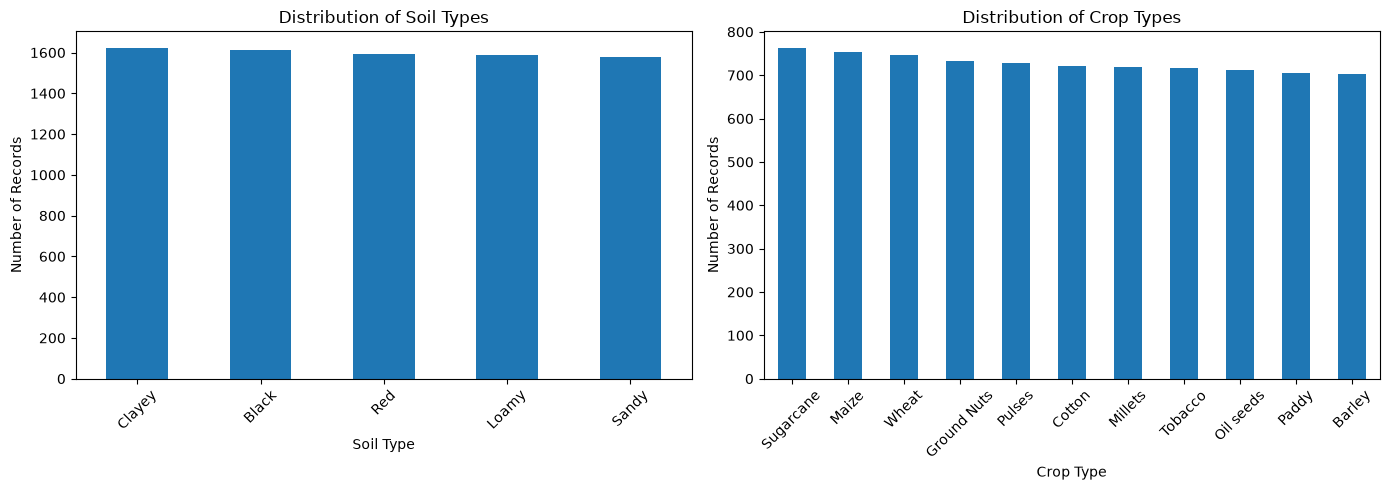

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["Soil Type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Distribution of Soil Types")
axes[0].set_ylabel("Number of Records")
axes[0].tick_params(axis="x", rotation=45)

df["Crop Type"].value_counts().plot(kind="bar", ax=axes[1])
axes[1].set_title("Distribution of Crop Types")
axes[1].set_ylabel("Number of Records")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(PLOT_DIR / "categorical_distributions.png")
plt.show()

## 3. Feature Engineering

In [4]:
df_work = df.copy()

df_work["Total_Nutrients"] = (
    df_work["Nitrogen"]
    + df_work["Phosphorous"]
    + df_work["Potassium"]
)

df_work["NPK_Imbalance"] = (
    df_work[["Nitrogen", "Phosphorous", "Potassium"]].max(axis=1)
    - df_work[["Nitrogen", "Phosphorous", "Potassium"]].min(axis=1)
)

df_work[
    ["Nitrogen", "Phosphorous", "Potassium",
     "Total_Nutrients", "NPK_Imbalance"]
].head()

,Nitrogen,Phosphorous,Potassium,Total_Nutrients,NPK_Imbalance
0,37,0,0,37,37
1,12,36,0,48,36
2,7,30,9,46,23
3,22,20,0,42,22
4,35,0,0,35,35


## 4. Outlier Detection

Q1: 0.0
Q3: 5.0
IQR: 5.0
Lower bound: -7.5
Upper bound: 12.5
Flagged Potassium values: 910

Decision: flagged values are retained because they are valid observations in the dataset.


/tmp/ipykernel_155015/2785445735.py:23: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df_work["Potassium"], vert=False)


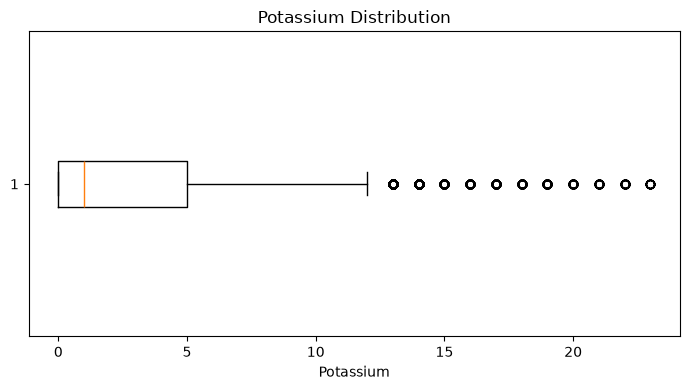

In [5]:
Q1 = df_work["Potassium"].quantile(0.25)
Q3 = df_work["Potassium"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

flagged = df_work[
    (df_work["Potassium"] < lower_bound) |
    (df_work["Potassium"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Flagged Potassium values:", len(flagged))

print("\nDecision: flagged values are retained because they are valid observations in the dataset.")

plt.figure(figsize=(7, 4))
plt.boxplot(df_work["Potassium"], vert=False)
plt.title("Potassium Distribution")
plt.xlabel("Potassium")
plt.tight_layout()
plt.savefig(PLOT_DIR / "potassium_boxplot.png")
plt.show()

## 5. Correlation and Feature Redundancy Analysis

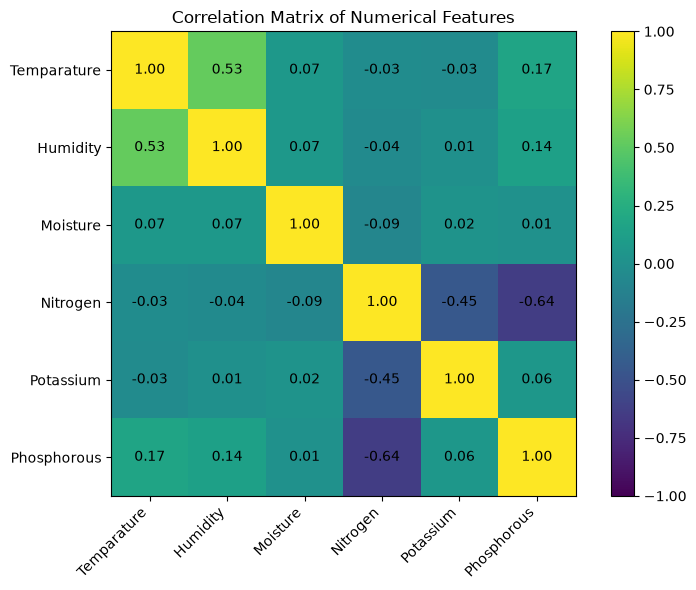

Feature pairs with |correlation| >= 0.85:
None

Decision: no numerical features are removed based on redundancy.


In [6]:
numeric_original = [
    "Temparature",
    "Humidity",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous"
]

corr = df_work[numeric_original].corr()

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(corr, vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}",
                ha="center", va="center")

fig.colorbar(image)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.savefig(PLOT_DIR / "correlation_heatmap.png")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = upper.stack()[upper.stack().abs() >= 0.85]

print("Feature pairs with |correlation| >= 0.85:")
print(high_corr if len(high_corr) else "None")

print("\nDecision: no numerical features are removed based on redundancy.")

## 6. Stratified Train-Test Split

Training shape: (6400, 10)
Testing shape: (1600, 10)
                 Full Dataset  Training  Testing
Fertilizer Name                                 
14-35-14                14.85     14.84    14.88
Urea                    14.62     14.62    14.62
DAP                     14.59     14.59    14.56
10-26-26                14.10     14.09    14.12
17-17-17                14.05     14.05    14.06
28-28                   14.00     14.00    14.00
20-20                   13.79     13.80    13.75


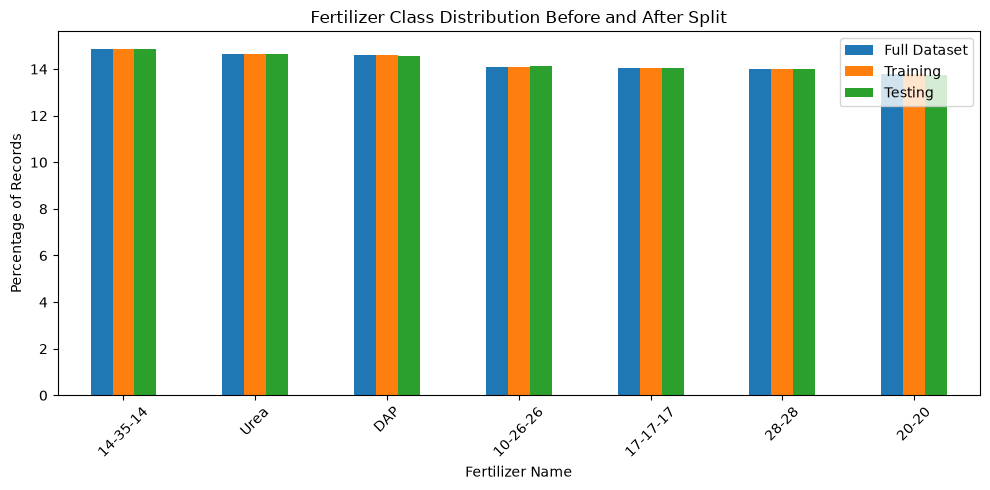

In [7]:
X = df_work.drop(columns=["Fertilizer Name"])
y = df_work["Fertilizer Name"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

distribution = pd.concat(
    [
        y.value_counts(normalize=True).rename("Full Dataset"),
        y_train.value_counts(normalize=True).rename("Training"),
        y_test.value_counts(normalize=True).rename("Testing")
    ],
    axis=1
) * 100

print(distribution.round(2))

distribution.plot(kind="bar", figsize=(10, 5))
plt.ylabel("Percentage of Records")
plt.title("Fertilizer Class Distribution Before and After Split")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(PLOT_DIR / "class_distribution_split.png")
plt.show()

## 7. Target Encoding

In [8]:
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

target_mapping = pd.DataFrame({
    "Fertilizer Name": label_encoder.classes_,
    "Encoded Label": label_encoder.transform(label_encoder.classes_)
})

target_mapping

,Fertilizer Name,Encoded Label
0,10-26-26,0
1,14-35-14,1
2,17-17-17,2
3,20-20,3
4,28-28,4
5,DAP,5
6,Urea,6


## 8. Feature Encoding and Scaling

In [9]:
numeric_features = [
    "Temparature",
    "Humidity",
    "Moisture",
    "Nitrogen",
    "Potassium",
    "Phosphorous",
    "Total_Nutrients",
    "NPK_Imbalance"
]

categorical_features = [
    "Soil Type",
    "Crop Type"
]

try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", one_hot, categorical_features)
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Original training features:", X_train.shape[1])
print("Processed training features:", X_train_processed.shape[1])
print("Training rows:", X_train_processed.shape[0])
print("Testing rows:", X_test_processed.shape[0])

Original training features: 10
Processed training features: 24
Training rows: 6400
Testing rows: 1600


## 9. Final Processed Outputs

In [10]:
train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

test_processed = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

train_processed["Fertilizer_Label"] = y_train_encoded
test_processed["Fertilizer_Label"] = y_test_encoded

train_processed.to_csv(
    OUTPUT_DIR / "train_processed.csv",
    index=False
)

test_processed.to_csv(
    OUTPUT_DIR / "test_processed.csv",
    index=False
)

target_mapping.to_csv(
    OUTPUT_DIR / "fertilizer_label_mapping.csv",
    index=False
)

print("Processed training data:", train_processed.shape)
print("Processed testing data:", test_processed.shape)

print("\nSaved outputs:")
print("- results/outputs/train_processed.csv")
print("- results/outputs/test_processed.csv")
print("- results/outputs/fertilizer_label_mapping.csv")

train_processed.head()

Processed training data: (6400, 25)
Processed testing data: (1600, 25)

Saved outputs:
- results/outputs/train_processed.csv
- results/outputs/test_processed.csv
- results/outputs/fertilizer_label_mapping.csv


,numeric__Temparature,numeric__Humidity,numeric__Moisture,numeric__Nitrogen,numeric__Potassium,numeric__Phosphorous,numeric__Total_Nutrients,numeric__NPK_Imbalance,categorical__Soil Type_Black,categorical__Soil Type_Clayey,...,categorical__Crop Type_Ground Nuts,categorical__Crop Type_Maize,categorical__Crop Type_Millets,categorical__Crop Type_Oil seeds,categorical__Crop Type_Paddy,categorical__Crop Type_Pulses,categorical__Crop Type_Sugarcane,categorical__Crop Type_Tobacco,categorical__Crop Type_Wheat,Fertilizer_Label
0,0.372128,0.464596,-0.706641,-0.796927,0.010998,1.916286,1.634317,1.260013,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,3
1,-0.048158,1.100487,-0.490063,-0.627633,-0.714630,-0.722512,-2.130262,-1.217459,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,4
2,-1.089931,-0.044854,-1.255251,-0.712280,-0.714630,-0.647118,-2.130262,-1.302889,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,0.150807,-1.742610,-0.982936,-0.796927,0.010998,-0.119359,-1.112808,-1.046598,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,4
4,0.463786,1.186418,0.500461,1.911785,-0.533223,-1.325666,0.209882,1.260013,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,2
